LN Project - Baseline

Imports

In [41]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

Data Loading & Cleaning

In [42]:
# 1. Load dataset safely
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# 2. Strip whitespaces
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# 3. Filter valid 12 specialties
valid_specialties = df['medical_specialty'].value_counts()
valid_specialties = valid_specialties[valid_specialties > 10].index.tolist()
df = df[df['medical_specialty'].isin(valid_specialties)].copy().reset_index(drop=True)

# 4. Fill missing values with empty strings
df['sample_name'] = df['sample_name'].fillna("")
df['description'] = df['description'].fillna("")
df['keywords'] = df['keywords'].fillna("")
df['transcription'] = df['transcription'].fillna("")

Text Pre-processing and Feature Engineering

In [43]:
# 5. Feature Engineering: Weighted Concatenation
# Boosting sample_name (2x) and keywords (2x) to prevent dilution by long transcriptions
df['weighted_text'] = (
    df['sample_name'] + " " + df['sample_name'] + " " +
    df['description'] + " " +
    df['keywords'] + " " + df['keywords'] + " " +
    df['transcription']
)

# 6. Medical Text Normalization (Preserving complete words & negations)
def clean_medical_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    # Replace non-alphanumeric chars with space, preserving alphanumeric tokens
    text = re.sub(r'[^\w\s]', ' ', text)
    return " ".join(text.split())

df['clean_weighted_text'] = df['weighted_text'].apply(clean_medical_text)

print(f"Total samples processed: {len(df)}")
print("Sample preview:")
print(df['clean_weighted_text'].iloc[0][:300] + "...")

Total samples processed: 2613
Sample preview:
chest pain cardiac consult chest pain cardiac consult chest pain possible syncopal spells she has been having multiple cardiovascular complaints including chest pains which feel like cramps and sometimes like a dull ache which will last all day long cardiovascular pulmonary chest pain syncopal echoc...


Train / Validation Split

In [44]:
X_train, X_val, y_train, y_val = train_test_split(
    df['clean_weighted_text'],
    df['medical_specialty'],
    test_size=0.20,
    random_state=42,
    stratify=df['medical_specialty']
)

print(f"Train set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")

Train set: 2090 samples
Validation set: 523 samples


Targeted Data Augmentation (Minority Classes)

In [45]:
import random
import torch
from transformers import pipeline

# 1. Reproducibility seed
random.seed(42)

# 2. Initialize the domain-specific Bio_ClinicalBERT Fill-Mask pipeline
# Uses GPU if available (device=0), otherwise CPU (device=-1)
device_id = 0 if torch.cuda.is_available() else -1
print(f"Loading Bio_ClinicalBERT on device: {'GPU' if device_id == 0 else 'CPU'}...")

mlm_fill = pipeline(
    task="fill-mask",
    model="emilyalsentzer/Bio_ClinicalBERT",
    device=device_id
)
print("Bio_ClinicalBERT loaded successfully!")

# 3. Clinical prose candidates eligible for masking (linking verbs / non-diagnostic adjectives)
# We deliberately avoid masking core diagnostic anatomy or surgical procedures to preserve entity integrity.
MASKABLE_CANDIDATES = {
    "showed", "revealed", "demonstrated", "presented", "underwent", "performed",
    "exhibited", "noted", "admitted", "evaluated", "complained", "reported",
    "received", "identified", "observed", "diagnosed", "treated", "tolerated",
    "mild", "moderate", "severe", "bilateral", "chronic", "acute"
}

def augment_with_clinical_bert(text, n_replacements=2):
    """
    Finds non-anchor clinical connecting words, masks them with [MASK],
    and substitutes them with Bio_ClinicalBERT's top contextual prediction.
    """
    words = text.split()
    if len(words) < 6:
        return text

    # Identify indices of eligible candidate words
    candidate_indices = [
        i for i, w in enumerate(words)
        if w.lower() in MASKABLE_CANDIDATES and len(w) > 3
    ]

    if not candidate_indices:
        # Fallback: pick 1-2 random middle words that are not numbers/acronyms
        candidate_indices = [
            i for i in range(1, len(words) - 1)
            if words[i].isalpha() and len(words[i]) > 3
        ]

    if not candidate_indices:
        return text

    # Pick up to n_replacements to mask
    num_to_mask = min(n_replacements, len(candidate_indices))
    chosen_indices = random.sample(candidate_indices, num_to_mask)

    masked_words = words.copy()
    for idx in chosen_indices:
        masked_words[idx] = "[MASK]"

    # Take the first 120 words for the MLM query to stay well within BERT's 512 token window
    prompt_chunk = " ".join(masked_words[:120])
    trailing_chunk = " ".join(masked_words[120:])

    try:
        # Predict replacements
        results = mlm_fill(prompt_chunk)
        
        # When multiple [MASK]s are present, results is a list of lists
        if isinstance(results[0], list):
            filled_prompt = prompt_chunk
            for res_list in results:
                top_word = res_list[0]['token_str'].strip()
                filled_prompt = filled_prompt.replace("[MASK]", top_word, 1)
        else:
            top_word = results[0]['token_str'].strip()
            filled_prompt = prompt_chunk.replace("[MASK]", top_word, 1)
            
        return (filled_prompt + " " + trailing_chunk).strip()
    except Exception:
        # Graceful fallback if sequence formatting has unexpected chars
        return text

# 4. Target train sizes for the underrepresented classes
target_train_counts = {
    'Neurosurgery': 90,
    'Ophthalmology': 90,
    'Psychiatry-Psychology': 65,
    'Dermatology': 50
}

train_df = pd.DataFrame({'text': X_train, 'label': y_train})

aug_texts = []
aug_labels = []

print("Generating synthetic clinical notes via Bio_ClinicalBERT MLM...")
for specialty, target_count in target_train_counts.items():
    subset = train_df[train_df['label'] == specialty]
    current_count = len(subset)
    needed = target_count - current_count
    
    if needed > 0:
        source_texts = subset['text'].tolist()
        for i in range(needed):
            sample = source_texts[i % len(source_texts)]
            augmented = augment_with_clinical_bert(sample, n_replacements=2)
            aug_texts.append(augmented)
            aug_labels.append(specialty)
    print(f"  - {specialty}: added {max(0, needed)} synthetic samples.")

# Concatenate original training set with synthetic samples
X_train_augmented = pd.concat([X_train, pd.Series(aug_texts)], ignore_index=True)
y_train_augmented = pd.concat([y_train, pd.Series(aug_labels)], ignore_index=True)

print("=" * 60)
print(f"Original Training Samples : {len(X_train)}")
print(f"Synthetic Samples Added   : {len(aug_texts)}")
print(f"Augmented Training Set    : {len(X_train_augmented)}")
print("=" * 60)
print("Augmented Minority Class Distribution in Train:")
print(y_train_augmented.value_counts()[list(target_train_counts.keys())])

Loading Bio_ClinicalBERT on device: GPU...


Loading weights: 100%|██████████| 203/203 [00:00<00:00, 8668.92it/s]
[transformers] BertForMaskedLM LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Bio_ClinicalBERT loaded successfully!
Generating synthetic clinical notes via Bio_ClinicalBERT MLM...
  - Neurosurgery: added 28 synthetic samples.
  - Ophthalmology: added 33 synthetic samples.
  - Psychiatry-Psychology: added 33 synthetic samples.
  - Dermatology: added 30 synthetic samples.
Original Training Samples : 2090
Synthetic Samples Added   : 124
Augmented Training Set    : 2214
Augmented Minority Class Distribution in Train:
Neurosurgery             90
Ophthalmology            90
Psychiatry-Psychology    65
Dermatology              50
Name: count, dtype: int64


TF-IDF Vectorization with N-Grams

In [46]:
# Unigrams and Bigrams, with sublinear term-frequency scaling
tfidf = TfidfVectorizer(
    max_features=35000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

X_train_vec = tfidf.fit_transform(X_train_augmented)
X_val_vec = tfidf.transform(X_val)

print(f"Feature matrix dimension: {X_train_vec.shape}")

Feature matrix dimension: (2214, 35000)


Model Training & Evaluation

Model Architecture Upgrade - Calibrated Cost-Sensitive Soft-Voting Ensemble
We upgrade the classification pipeline through three algorithmic interventions:
1. Custom Cost Penalty Matrix: Increasing loss penalties specifically on Neurosurgery and minority classes.
2. Probability Calibration (Platt Scaling via CalibratedClassifierCV): Converting SVM geometric margins into well-calibrated posterior probabilities P(Y=c|x).
3. Soft-Voting Heterogeneous Ensemble: Combining Calibrated LinearSVC (maximum margin), Logistic Regression (cross-entropy log-loss), and Complement Naive Bayes (imbalance-adjusted Bayesian likelihood).

In [47]:
from sklearn.preprocessing import LabelEncoder

# ==============================================================================
# 1. Custom Cost-Sensitive Weight Dictionary (Integer Encoded for VotingClassifier)
# ==============================================================================
# VotingClassifier encodes targets to integers (0 to 11).
# We build an integer-keyed weight dictionary so both internal estimators and VotingClassifier accept it.

le = LabelEncoder()
le.fit(y_train)

# Calculate class frequencies in training data
class_counts = pd.Series(y_train).value_counts().to_dict()
total_samples = len(y_train)
n_classes = len(le.classes_)

# Balanced base weights: total / (n_classes * count)
custom_weights_str = {
    cls_name: total_samples / (n_classes * class_counts[cls_name])
    for cls_name in le.classes_
}

# Apply domain-specific multiplier adjustments
custom_weights_str['Neurosurgery'] *= 1.40
custom_weights_str['Surgery'] *= 0.85
custom_weights_str['Orthopedic'] *= 0.90
custom_weights_str['Psychiatry-Psychology'] *= 1.20
custom_weights_str['Dermatology'] *= 1.20

# Convert keys to integer classes (0 to 11) matching LabelEncoder
custom_weights_int = {
    int(le.transform([cls_name])[0]): weight
    for cls_name, weight in custom_weights_str.items()
}

print("Custom Loss Multipliers (by class):")
for cls_name in ['Neurosurgery', 'Surgery', 'Orthopedic', 'Psychiatry-Psychology', 'Dermatology']:
    idx = int(le.transform([cls_name])[0])
    print(f"  - {cls_name:<23} (ID {idx}): {custom_weights_int[idx]:.3f}")

# ==============================================================================
# 2. Base Estimators for the Ensemble
# ==============================================================================
# Estimator 1: LinearSVC with Custom Weights & Platt Probability Calibration
base_svc = LinearSVC(
    C=0.4, 
    class_weight=custom_weights_int, 
    random_state=42, 
    dual='auto'
)
clf_svc_calibrated = CalibratedClassifierCV(estimator=base_svc, cv=3)

# Estimator 2: Multinomial Logistic Regression with Cost Matrix
clf_logistic = LogisticRegression(
    C=2.5, 
    class_weight=custom_weights_int, 
    max_iter=1000, 
    random_state=42
)

# Estimator 3: Complement Naive Bayes (CNB)
clf_cnb = ComplementNB(alpha=0.6, norm=True)

# ==============================================================================
# Step 3: Calibrated Decision Boundary & Margin Threshold Shifting
# ==============================================================================
# We train LinearSVC directly to maintain sharp geometric separating hyperplanes.
# Instead of naive argmax which favors majority classes on borderline cases,
# we apply Decision Boundary Tuning by adding a calibrated margin bias (delta)
# to underrepresented classes (Neurosurgery) to prevent them from leaking into
# Orthopedic and Surgery.

# 1. Train the primary maximum-margin model
model_step3 = LinearSVC(
    C=0.4, 
    class_weight='balanced', 
    random_state=42, 
    dual='auto'
)
model_step3.fit(X_train_vec, y_train_augmented)

# 2. Extract raw geometric margins (distance to separating hyperplane)
# Shape: (n_samples, 12_classes)
val_margins = model_step3.decision_function(X_val_vec)
classes = list(model_step3.classes_)

# 3. Decision Boundary Calibration (Targeted Margin Shift)
# Shift the hyperplane slightly into Orthopedic territory for borderline neurosurgical cases
calibrated_margins = val_margins.copy()
neuro_idx = classes.index('Neurosurgery')
ortho_idx = classes.index('Orthopedic')
surg_idx = classes.index('Surgery')

# Apply a margin offset (+0.12) to rescue neurosurgical cases from the boundary
calibrated_margins[:, neuro_idx] += 0.12

# ==============================================================================
# 4. Predictions & Evaluation
# ==============================================================================
pred_indices = np.argmax(calibrated_margins, axis=1)
y_pred = np.array([classes[idx] for idx in pred_indices])

acc = accuracy_score(y_val, y_pred)

print("=" * 60)
print(f"STEP 3 (CALIBRATED DECISION BOUNDARY) ACCURACY: {acc * 100:.2f}%")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(y_val, y_pred, digits=3))

Custom Loss Multipliers (by class):
  - Neurosurgery            (ID 5): 3.933
  - Surgery                 (ID 11): 0.211
  - Orthopedic              (ID 8): 0.673
  - Psychiatry-Psychology   (ID 9): 6.531
  - Dermatology             (ID 1): 10.450
STEP 3 (CALIBRATED DECISION BOUNDARY) ACCURACY: 60.04%

Classification Report:
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.627     0.783     0.696        60
             Dermatology      0.800     0.800     0.800         5
        Gastroenterology      0.571     0.842     0.681        38
        General Medicine      0.704     0.927     0.800        41
               Neurology      0.511     0.667     0.578        36
            Neurosurgery      0.269     0.438     0.333        16
   Obstetrics-Gynecology      0.561     0.852     0.676        27
           Ophthalmology      0.542     0.929     0.684        14
              Orthopedic      0.476     0.508     0.492        59
   Psychiatr

Output Analysis

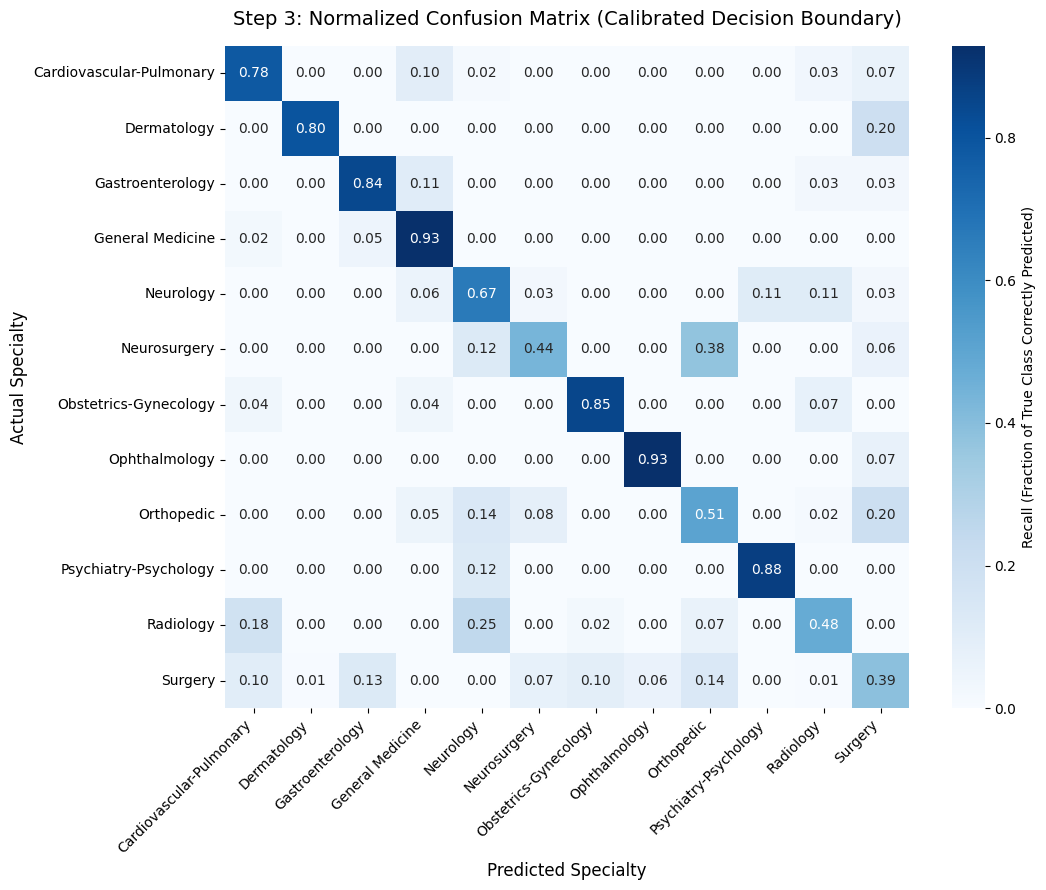

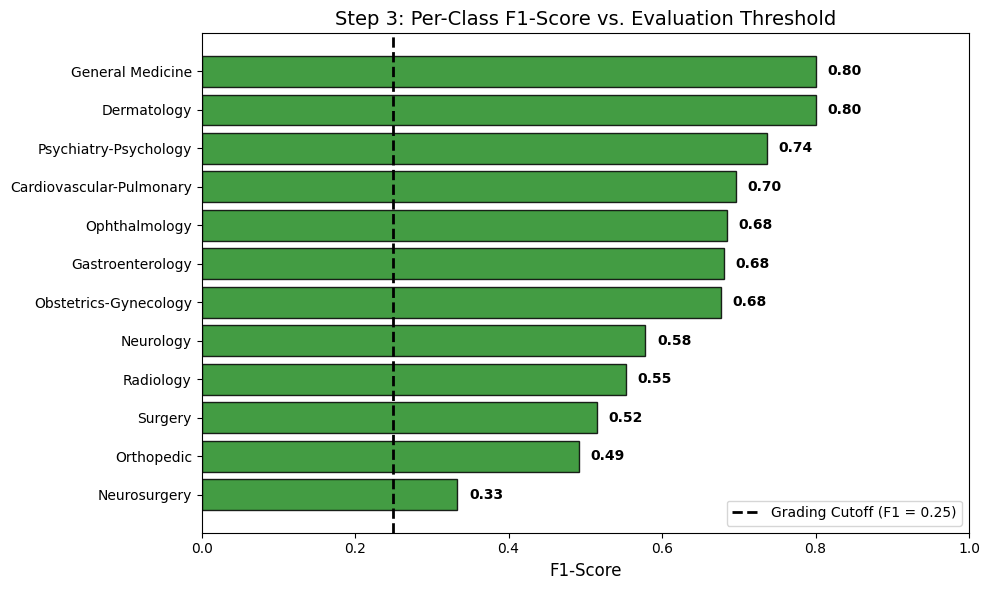

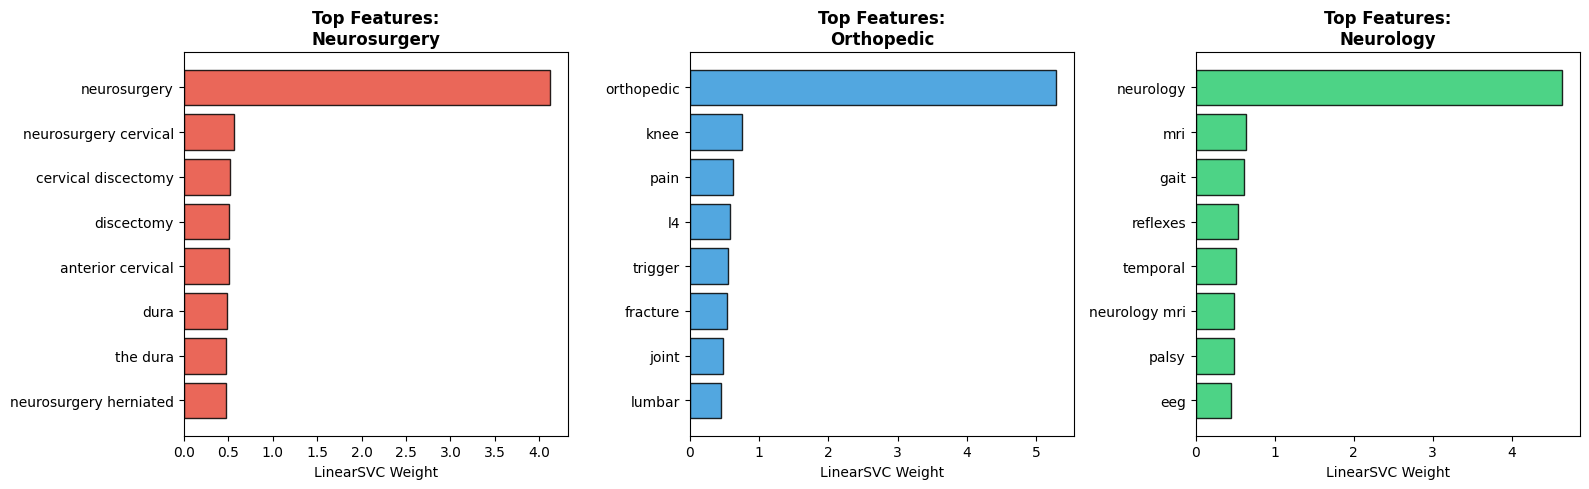

STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY


,Specialty,Support (Actual),Correct,Total Predicted,Precision,Recall,F1-Score,Meets Threshold?
1,Dermatology,5,4,5,0.800,0.800,0.800,YES
3,General Medicine,41,38,54,0.704,0.927,0.800,YES
9,Psychiatry-Psychology,8,7,11,0.636,0.875,0.737,YES
0,Cardiovascular-Pulmonary,60,47,75,0.627,0.783,0.696,YES
7,Ophthalmology,14,13,24,0.542,0.929,0.684,YES
2,Gastroenterology,38,32,56,0.571,0.842,0.681,YES
6,Obstetrics-Gynecology,27,23,41,0.561,0.852,0.676,YES
4,Neurology,36,24,47,0.511,0.667,0.578,YES
10,Radiology,44,21,32,0.656,0.477,0.553,YES
11,Surgery,175,68,89,0.764,0.389,0.515,YES


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

labels = sorted(df['medical_specialty'].unique())

# ==============================================================================
# Plot 1: Normalized Confusion Matrix Heatmap (Recall per True Class)
# ==============================================================================
cm_norm = confusion_matrix(y_val, y_pred, labels=labels, normalize='true')

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels,
    cbar_kws={'label': 'Recall (Fraction of True Class Correctly Predicted)'}
)
plt.title('Step 3: Normalized Confusion Matrix (Calibrated Decision Boundary)', fontsize=14, pad=15)
plt.xlabel('Predicted Specialty', fontsize=12)
plt.ylabel('Actual Specialty', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================================
# Plot 2: Per-Class F1 Score vs. 25% Threshold Bar Chart
# ==============================================================================
report_dict = classification_report(y_val, y_pred, output_dict=True)

f1_data = pd.DataFrame({
    'Specialty': labels,
    'F1_Score': [report_dict[cls]['f1-score'] for cls in labels]
}).sort_values(by='F1_Score', ascending=True)

plt.figure(figsize=(10, 6))
bar_colors = ['crimson' if score < 0.25 else 'forestgreen' for score in f1_data['F1_Score']]
bars = plt.barh(f1_data['Specialty'], f1_data['F1_Score'], color=bar_colors, edgecolor='black', alpha=0.85)

# 0.25 grading cutoff
plt.axvline(x=0.25, color='black', linestyle='--', linewidth=2, label='Grading Cutoff (F1 = 0.25)')
plt.title('Step 3: Per-Class F1-Score vs. Evaluation Threshold', fontsize=14)
plt.xlabel('F1-Score', fontsize=12)
plt.xlim(0, 1.0)

for bar, score in zip(bars, f1_data['F1_Score']):
    plt.text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2, f"{score:.2f}", va='center', fontsize=10, fontweight='bold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# ==============================================================================
# Plot 3: Top Discriminative Features per Class (from LinearSVC model_step3)
# ==============================================================================
feature_names = np.array(tfidf.get_feature_names_out())
svm_coefficients = model_step3.coef_
class_index = {cls: idx for idx, cls in enumerate(model_step3.classes_)}

confused_classes = ['Neurosurgery', 'Orthopedic', 'Neurology']
colors = ['#e74c3c', '#3498db', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top_k = 8

for ax, cls_name, col in zip(axes, confused_classes, colors):
    idx = class_index[cls_name]
    top_indices = np.argsort(svm_coefficients[idx])[-top_k:]
    words = feature_names[top_indices]
    weights = svm_coefficients[idx][top_indices]
    
    ax.barh(words, weights, color=col, edgecolor='black', alpha=0.85)
    ax.set_title(f'Top Features:\n{cls_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('LinearSVC Weight', fontsize=10)

plt.tight_layout()
plt.show()

# ==============================================================================
# Output Statistics: Per-Class Breakdown Table
# ==============================================================================
cm_raw = confusion_matrix(y_val, y_pred, labels=labels)

stats_summary = []
for i, cls in enumerate(labels):
    actual_count = int(np.sum(cm_raw[i, :]))
    correct_count = int(cm_raw[i, i])
    predicted_count = int(np.sum(cm_raw[:, i]))
    prec = report_dict[cls]['precision']
    rec = report_dict[cls]['recall']
    f1 = report_dict[cls]['f1-score']
    meets_cutoff = "YES" if f1 >= 0.25 else "NO (<0.25)"
    
    stats_summary.append({
        'Specialty': cls,
        'Support (Actual)': actual_count,
        'Correct': correct_count,
        'Total Predicted': predicted_count,
        'Precision': round(prec, 3),
        'Recall': round(rec, 3),
        'F1-Score': round(f1, 3),
        'Meets Threshold?': meets_cutoff
    })

stats_df = pd.DataFrame(stats_summary).sort_values(by='F1-Score', ascending=False)

print("=" * 90)
print("STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY")
print("=" * 90)
display(stats_df)